## 의류 이미지 분류: 하이퍼파라미터 실험

Fashion-MNIST의 10개 품목을 분류하는 CNN의 실험 결과다.

### 변경할 수 있는 하이퍼파라미터

이 코드에서 조절할 수 있는 항목은 다음과 같다.

| 변경 항목 | 코드의 설정 이름 | 공통 설정 | 비교할 값 |
| --- | --- | --- | --- |
| 학습률 | `learning_rate` | 0.001 | 0.0003, 0.003 |
| 배치 크기 | `batch_size` | 64 | 32, 128 |
| 에포크 수 | `epochs` | 5 | 3, 10 |
| 첫 합성곱 필터 수 | `channels` | 32 | 16, 64 |
| 은닉 노드 수 | `hidden_units` | 128 | 64, 256 |

두 번째 합성곱의 필터 수는 첫 번째의 두 배다.

공통 설정에서 한 항목씩 바꾼다. 데이터 분할과 시드는 모두 같게 유지하고, 각 조건마다 모델과 학습용 배치를 새로 만든다. 각 실험에서는 검증 손실이 가장 작았던 에포크의 가중치를 사용한다.

In [1]:
import time
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import FashionMNIST
from torchvision.transforms import v2

# 난수 시드를 고정한다.
SEED = 42
torch.manual_seed(SEED)

### 데이터 준비

In [2]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

fashion_train = FashionMNIST(root="image_data", train=True, download=True, transform=transform)
fashion_test = FashionMNIST(root="image_data", train=False, download=True, transform=transform)
exercise_classes = fashion_train.classes

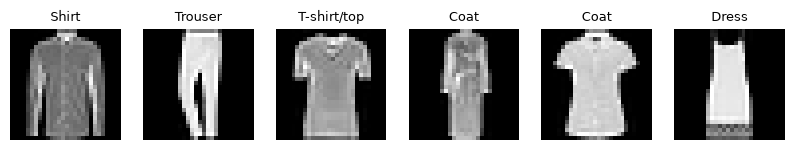

학습·검증·테스트 이미지 수: 6000 1000 1000


In [3]:
# 품목별 비율을 유지하며 학습·검증·테스트 인덱스를 선택한다.
exercise_labels = fashion_train.targets.numpy()
exercise_train_idx, exercise_remaining = train_test_split(
    np.arange(len(fashion_train)), train_size=6000, stratify=exercise_labels, random_state=SEED,
)
exercise_val_idx, _ = train_test_split(
    exercise_remaining, train_size=1000, stratify=exercise_labels[exercise_remaining], random_state=SEED,
)
exercise_test_idx, _ = train_test_split(
    np.arange(len(fashion_test)), train_size=1000,
    stratify=fashion_test.targets.numpy(), random_state=SEED,
)
exercise_train = Subset(fashion_train, exercise_train_idx.tolist())
exercise_val = Subset(fashion_train, exercise_val_idx.tolist())
exercise_test = Subset(fashion_test, exercise_test_idx.tolist())

exercise_train_eval = DataLoader(exercise_train, batch_size=128)
exercise_val_loader = DataLoader(exercise_val, batch_size=128)
exercise_test_loader = DataLoader(exercise_test, batch_size=128)

# 시각화: 의류 이미지 6장과 정답 품목을 확인한다.
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    exercise_image, exercise_label = exercise_train[i]
    ax.imshow(exercise_image[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(exercise_classes[exercise_label], fontsize=9)
    ax.axis("off")
plt.show()
print("학습·검증·테스트 이미지 수:", len(exercise_train), len(exercise_val), len(exercise_test))

### 모델과 학습 함수

In [4]:
def make_cnn(channels=32, hidden_units=128):
    return nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=channels, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(in_channels=channels, out_channels=channels * 2, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Flatten(),
        nn.Linear(channels * 2 * 5 * 5, hidden_units),
        nn.ReLU(),
        nn.Linear(hidden_units, 10),
    )

In [5]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for inputs, labels in loader:

        logits = model(inputs)
        loss = nn.functional.cross_entropy(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(labels)

        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)
    return loss_sum / count, correct / count

In [6]:
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for inputs, labels in loader:
        logits = model(inputs)
        loss = nn.functional.cross_entropy(logits, labels)
        loss_sum += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)

    return loss_sum / count, correct / count

In [7]:
def fit_classifier(model, train_loader, train_eval_loader, val_loader, epochs=5, lr=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    best_loss, best_state = float("inf"), None
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)

        # 에포크 종료 시점의 같은 가중치로 학습·검증 손실을 비교한다.
        train_eval_loss, _ = evaluate_classifier(model, train_eval_loader)
        val_loss, val_acc = evaluate_classifier(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": train_loss,
                        "train_eval_loss": train_eval_loss, "val_loss": val_loss, "train_accuracy": train_acc, "val_accuracy": val_acc})

        if val_loss < best_loss:
            best_loss, best_state = val_loss, deepcopy(model.state_dict())
        print(f"epoch={epoch+1} train_loss={train_loss:.3f} val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    model.load_state_dict(best_state)
    return pd.DataFrame(history)

In [8]:
def train_and_evaluate(name, model, train_dataset, train_eval_loader, val_loader):

    loader = DataLoader(
        train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
        generator=torch.Generator().manual_seed(CONFIG["seed"]),
    )

    start = time.perf_counter()
    trace = fit_classifier(
        model, loader, train_eval_loader, val_loader,
        epochs=CONFIG["epochs"], lr=CONFIG["learning_rate"],
    )
    seconds = time.perf_counter() - start
    val_loss, val_accuracy = evaluate_classifier(model, val_loader)

    row = {"condition": name, "parameters": sum(p.numel() for p in model.parameters()),
           "val_loss": val_loss, "val_accuracy": val_accuracy, "seconds": seconds}
    return trace, row

In [9]:
common_config = {
    "seed": SEED, "epochs": 5, "learning_rate": 0.001,
    "batch_size": 64, "channels": 32, "hidden_units": 128,
}
experiments = [
    ("common", {}),
    ("lr_0.0003", {"learning_rate": 0.0003}),
    ("lr_0.003", {"learning_rate": 0.003}),
    ("batch_32", {"batch_size": 32}),
    ("batch_128", {"batch_size": 128}),
    ("epochs_3", {"epochs": 3}),
    ("epochs_10", {"epochs": 10}),
    ("channels_16", {"channels": 16}),
    ("channels_64", {"channels": 64}),
    ("hidden_64", {"hidden_units": 64}),
    ("hidden_256", {"hidden_units": 256}),
]
models, histories, results = {}, {}, []

### 조건별 학습

In [10]:
for name, changes in experiments:
    # 공통 설정을 복사한 뒤 이번 실험의 한 항목만 변경한다.
    CONFIG = common_config.copy()
    CONFIG.update(changes)
    print(f"\n[{name}]")

    # 새 가중치와 같은 시드에서 학습을 시작한다.
    torch.manual_seed(CONFIG["seed"])
    model = make_cnn(CONFIG["channels"], CONFIG["hidden_units"])
    history, result = train_and_evaluate(
        name, model, exercise_train, exercise_train_eval, exercise_val_loader,
    )

    # 복원된 모델과 에포크별 기록을 보관한다.
    models[name] = model
    histories[name] = history
    best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])
    result.update(CONFIG)
    result["best_epoch"] = best_epoch
    results.append(result)


[common]


epoch=1 train_loss=1.065 val_loss=0.736 val_acc=0.711


epoch=2 train_loss=0.622 val_loss=0.653 val_acc=0.760


epoch=3 train_loss=0.539 val_loss=0.550 val_acc=0.788


epoch=4 train_loss=0.470 val_loss=0.524 val_acc=0.798


epoch=5 train_loss=0.429 val_loss=0.505 val_acc=0.806

[lr_0.0003]


... (49 outputs left out)

epoch=2 train_loss=0.613 val_loss=0.624 val_acc=0.764


epoch=3 train_loss=0.530 val_loss=0.554 val_acc=0.789


epoch=4 train_loss=0.466 val_loss=0.493 val_acc=0.806


epoch=5 train_loss=0.430 val_loss=0.489 val_acc=0.812


### 검증 결과 비교

손실·정확도는 각 실험에서 복원한 모델의 결과다. 소요 시간에는 전체 에포크의 학습과 평가가 포함된다.

In [11]:
comparison = pd.DataFrame(results).sort_values("val_loss").reset_index(drop=True)
display(comparison[[
    "condition", "learning_rate", "batch_size", "epochs", "channels", "hidden_units",
    "best_epoch", "val_loss", "val_accuracy", "parameters", "seconds",
]].round(4))

,condition,learning_rate,batch_size,epochs,channels,hidden_units,best_epoch,val_loss,val_accuracy,parameters,seconds
0,epochs_10,0.0010,64,10,32,128,8,0.4471,0.834,225034,18.0835
1,channels_64,0.0010,64,5,64,128,4,0.4496,0.834,485514,20.5296
2,lr_0.003,0.0030,64,5,32,128,4,0.4529,0.830,225034,9.1712
3,hidden_256,0.0010,64,5,32,256,5,0.4890,0.812,431242,9.0083
4,batch_32,0.0010,32,5,32,128,4,0.4976,0.794,225034,9.2324
5,common,0.0010,64,5,32,128,5,0.5049,0.806,225034,10.6422
6,hidden_64,0.0010,64,5,32,64,5,0.5321,0.790,121930,9.3726
7,batch_128,0.0010,128,5,32,128,5,0.5355,0.794,225034,9.4634
8,channels_16,0.0010,64,5,16,128,5,0.5487,0.777,108618,6.0594
9,epochs_3,0.0010,64,3,32,128,3,0.5499,0.788,225034,5.3624


### 학습 곡선 비교

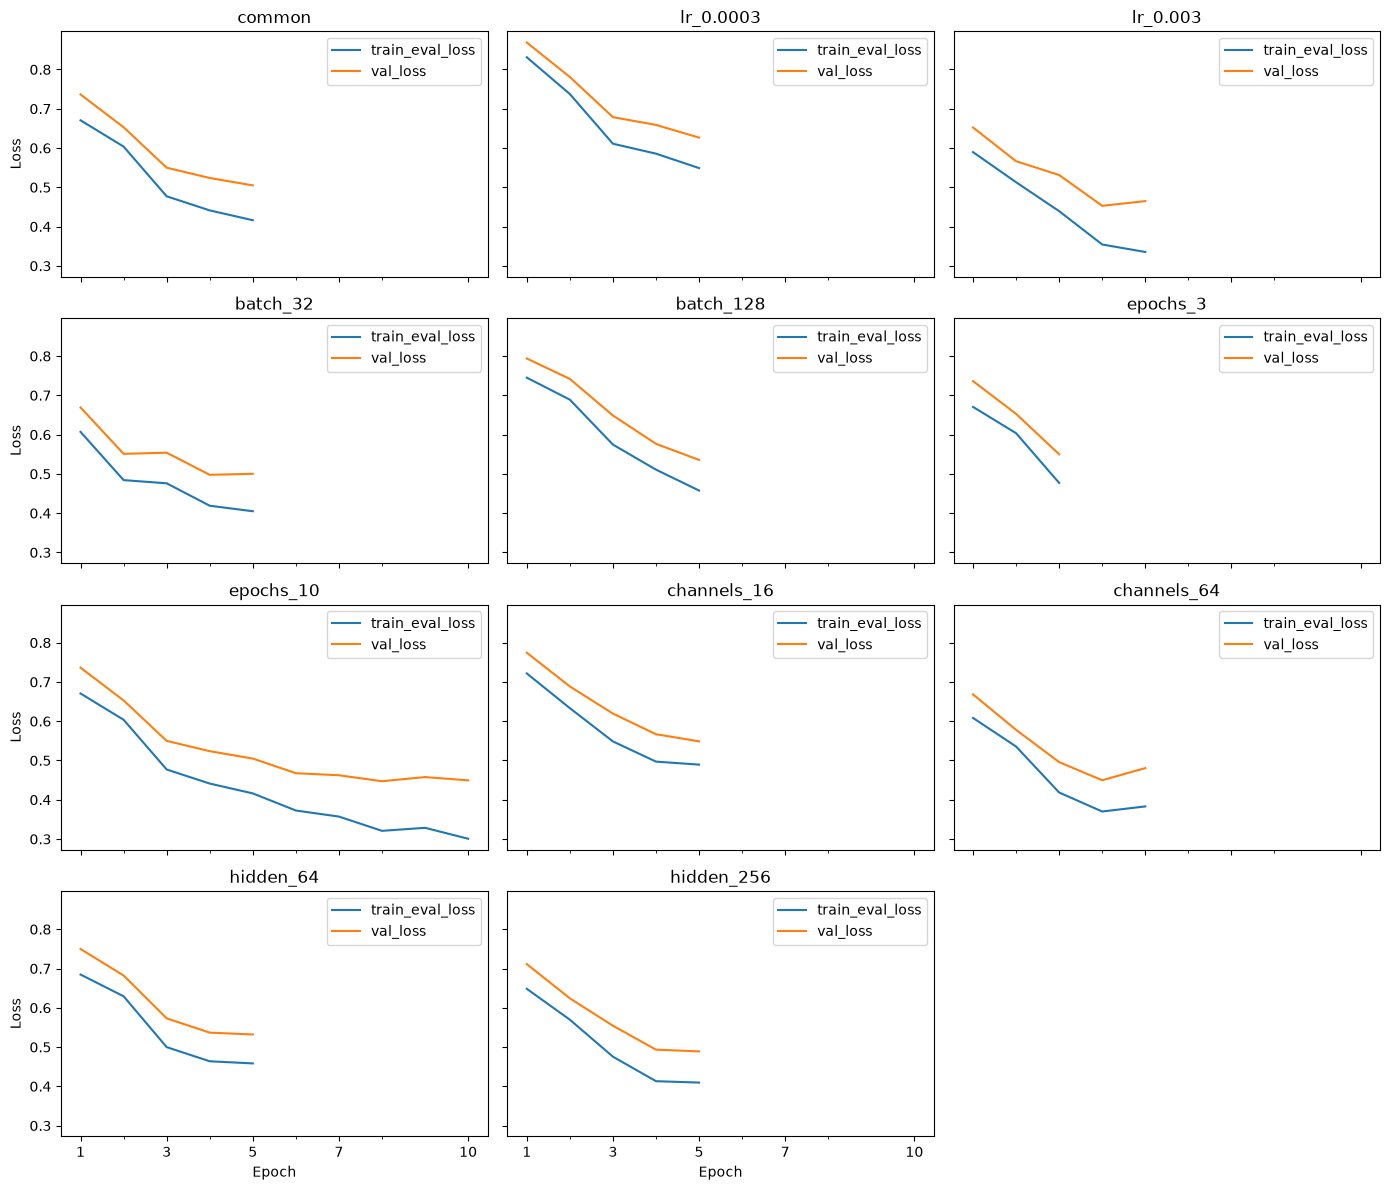

In [12]:
# 시각화: 모든 조건의 학습·검증 손실을 같은 축 범위로 비교한다.
fig, axes = plt.subplots(4, 3, figsize=(14, 12), sharex=True, sharey=True)
for ax, (name, _) in zip(axes.ravel(), experiments):
    history = histories[name]
    history.plot(x="epoch", y=["train_eval_loss", "val_loss"], ax=ax, title=name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks([1, 3, 5, 7, 10])

for ax in axes.ravel()[len(experiments):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 실험 결과 해석

| 변경 항목 | 관찰한 결과 |
| --- | --- |
| 학습률 | 0.0003은 공통 설정보다 학습이 느렸다. 0.003은 모델 크기를 유지하면서 검증 손실을 낮췄지만, 마지막 에포크에서는 학습 손실이 줄고 검증 손실은 올라갔다. |
| 배치 크기 | 32는 공통 설정보다 검증 손실이 조금 낮았지만 정확도도 낮았다. 같은 에포크 수에서도 배치 크기에 따라 가중치 갱신 횟수가 달라진다. |
| 에포크 수 | 학습 기간을 늘릴수록 최소 검증 손실이 낮아졌다. 10에포크 조건에서는 후반부 학습 손실 감소에 비해 검증 손실의 개선이 둔해졌다. |
| 필터 수 | 필터 수를 늘리면 검증 손실이 낮아졌고, 파라미터 수와 실행 시간도 늘었다. |
| 은닉 노드 수 | 256개 조건은 공통 설정보다 정확도가 0.6%p 높았고, 파라미터 수는 약 1.9배였다. |

10에포크 조건의 8에포크에서 전체 실험 중 가장 작은 검증 손실 0.4471을 얻었다. 10에포크 시점의 정확도는 84.6%였지만, 선택 기준인 검증 손실에 따라 8에포크의 가중치와 정확도 83.4%를 최종 비교에 사용했다.


### 최종 모델 선택

In [13]:
# 검증 손실이 가장 작은 조건의 복원된 모델을 선택한다.
selected_name = comparison.iloc[0]["condition"]
selected_model = models[selected_name]
print("선택한 조건:", selected_name)
display(comparison.loc[comparison["condition"] == selected_name].round(4))

선택한 조건: epochs_10


,condition,parameters,val_loss,val_accuracy,seconds,seed,epochs,learning_rate,batch_size,channels,hidden_units,best_epoch
0,epochs_10,225034,0.4471,0.834,18.0835,42,10,0.001,64,32,128,8


### 혼동행렬과 오분류 이미지

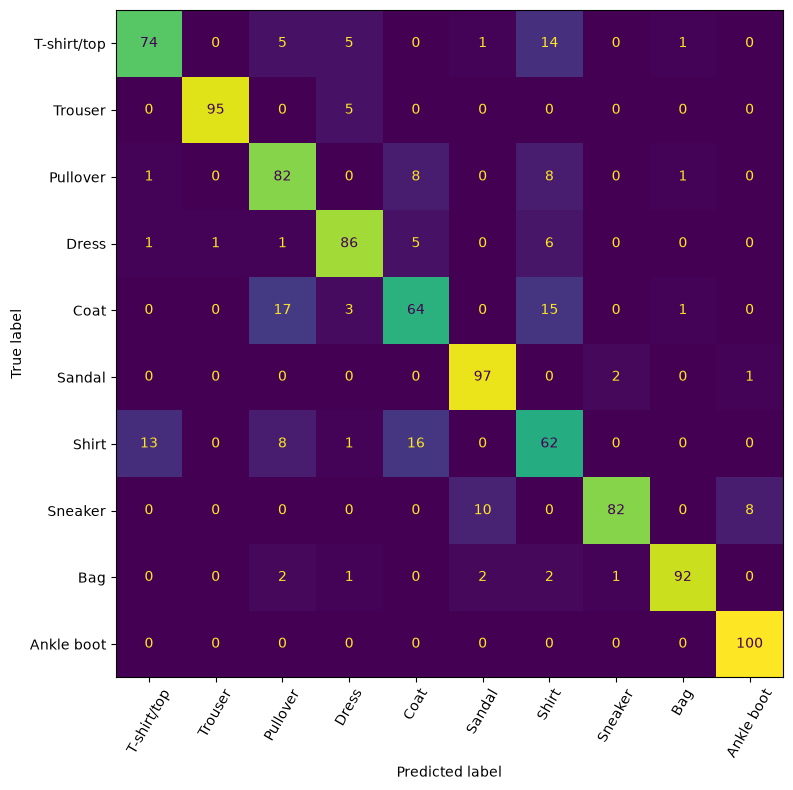

검증 오분류 수: 166
가장 많은 혼동: Coat → Pullover (17장)


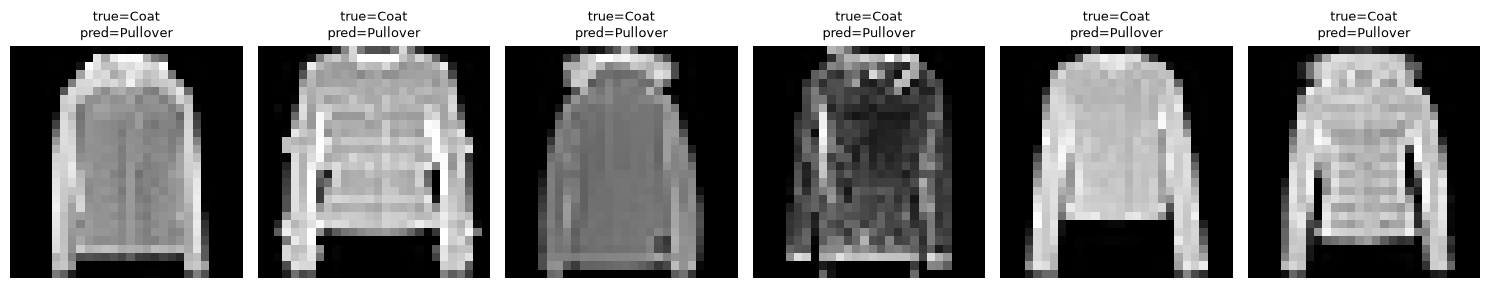

In [14]:
val_images, val_labels = next(iter(DataLoader(exercise_val, batch_size=len(exercise_val))))

# 예측: 검증 배치별 예측 품목을 원래 이미지 순서대로 이어 붙인다.
selected_model.eval()
with torch.no_grad():
    pred = torch.cat([selected_model(xb).argmax(1) for xb, _ in exercise_val_loader]).numpy()

# 시각화: 실제 품목을 행, 예측 품목을 열로 하는 혼동행렬을 그린다.
confusion = confusion_matrix(val_labels.numpy(), pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion, display_labels=exercise_classes).plot(ax=ax, xticks_rotation=60, colorbar=False)
plt.tight_layout()
plt.show()

# 분석: 틀린 이미지 중 가장 많이 혼동한 실제 품목 → 예측 품목 조합을 찾는다.
wrong_positions = np.flatnonzero(pred != val_labels.numpy())
print("검증 오분류 수:", len(wrong_positions))
if len(wrong_positions):
    off_diagonal = confusion.copy()
    np.fill_diagonal(off_diagonal, 0)  # 맞힌 사례를 제외하고 가장 큰 혼동을 찾는다.

    # 최댓값의 위치를 실제 품목의 행, 예측 품목의 열로 변환한다.
    actual_class, predicted_class = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    chosen = np.flatnonzero(
        (val_labels.numpy() == actual_class) & (pred == predicted_class)
    )[:6]
    print(f"가장 많은 혼동: {exercise_classes[actual_class]} → {exercise_classes[predicted_class]} "
          f"({confusion[actual_class, predicted_class]}장)")

    # 시각화: 해당 조합으로 틀린 이미지를 최대 6장 표시한다.
    fig, axes = plt.subplots(1, len(chosen), figsize=(2.5 * len(chosen), 3), squeeze=False)
    for ax, index in zip(axes.ravel(), chosen):
        ax.imshow(val_images[index, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"true={exercise_classes[val_labels[index]]}\npred={exercise_classes[pred[index]]}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("검증 이미지에서 오분류가 없습니다.")

### 오분류 해석

검증 이미지 1,000장 중 166장을 틀렸다. 가장 많은 혼동은 코트(Coat)를 풀오버(Pullover)로 예측한 17장이었고, 셔츠(Shirt)를 코트로 예측한 경우도 16장이었다.

표시된 코트 사례에서는 몸통과 긴 소매의 윤곽이 비슷하게 보인다. 작은 흑백 이미지에서 이러한 형태의 유사성이 혼동에 영향을 주었을 가능성이 있다. 오류는 코트·셔츠·티셔츠 등 상의 품목 사이에서 많이 관찰됐다.

### 최종 테스트

선택한 모델을 테스트 데이터에서 한 번 평가한다.

In [15]:
final_results = []
for split, loader in [("train", exercise_train_eval), ("test", exercise_test_loader)]:
    loss, accuracy = evaluate_classifier(selected_model, loader)
    final_results.append({"split": split, "loss": loss, "accuracy": accuracy})
print("선택한 조건:", selected_name)
display(pd.DataFrame(final_results).round(4))

선택한 조건: epochs_10


,split,loss,accuracy
0,train,0.3208,0.8813
1,test,0.4068,0.8630
